# Dubstrata Quantitative Evaluation Kit: 12-Month Multi-Regime Point-in-Time (PIT) Walk-Forward Workbench

This notebook provides **independent, zero-trust quantitative verification** of the Dubstrata 16-channel multivariate tensor and its **De-Sybiled Prediction Market (PM) Layer** across a **full 12-month multi-regime 5-minute dataset (`105,120` bars: `2025-09-22` to `2026-09-22` UTC)**.

Rather than relying on pre-computed model outputs from an API or static structural priors, this workbench operates directly on the bundled **raw point-in-time 5-minute historical partition** (`data/dubstrata_btc_pit_5m_sample.parquet`, **105,120 bars / 365 days**) containing:
1. **All 4 Bi-Temporal Timestamps on Every Row**:
   - `t_valid` (`window_start`): Start of the 5-minute observation validity interval ($T_{\text{bar\_close}} - 300\text{s}$).
   - `t_event`: Final source matching-engine / Polygon CTF block / EDGAR event timestamp inside the bar ($T_{\text{valid}} < T_{\text{event}}$).
   - `t_ingest`: Immutable datastore transaction commit timestamp ($T_{\text{event}} < T_{\text{ingest}} \le T_{\text{bar\_close}}$). Any event with $T_{\text{ingest}} > T_{\text{bar\_close}}$ is hard-gated out of bar $t$ and deferred to bar $t+1$.
   - `bar_close_time` (`window_end`): The 5-minute bar decision cutoff $T_{\text{bar\_close}}$.
2. **Raw Un-Differentiated BTC Spot OHLCV Prices (`btc_open`, `btc_high`, `btc_low`, `btc_close`, `btc_volume`)**:
   - All forward return targets and backtest trades enforce a **strict 1-bar execution delay**, entering at the next bar's open (`btc_open` at $t+1$) after bar $t$ closes and commits:
     $$r_{t+1 \to t+1+h}^{\text{exec}} = \frac{\text{btc\_open}_{t+1+h}}{\text{btc\_open}_{t+1}} - 1$$
3. **Methodological Guarantees Enforced in This Workbench**:
   - **Zero Static Priors ($\mathbf{w}_{\text{prior}} = \mathbf{0}$)**: Walk-forward estimation uses 100% unconstrained out-of-sample Ridge regression (`StandardScaler + Ridge`) fitted strictly on purged historical training windows (`purge = HORIZON_BARS + 1`).
   - **Monotonic Rank Correlation Alignment**: Both **Pearson IC** and **Spearman Rank IC** are evaluated side by side across all horizons (`15m`, `1h`, `4h`) and across all 12 monthly regimes (`2025-10` to `2026-09`).
   - **No EMA Position Smoothing & Explicit Lo (2002) / Newey-West Sharpe Adjustment**: Discrete conviction-gated hysteresis controls turnover transparently without `ewm` serial-correlation inflation, reporting both standard annualized Sharpe and **Lo (2002) / Newey-West autocorrelation-adjusted Sharpe ($\text{SR}_{\text{NW}}(q=6)$)** under both **Blended (`3.5 bps`)** and **Taker (`6.5 bps`)** cost schedules.

---

### Evaluation Modules
- **Module 1**: 12-Month Multi-Regime PIT Dataset Loader & Custom Window Selector (`START_TIME`, `END_TIME`)
- **Module 2**: 4-Timestamp Bi-Temporal Audit (`105,120` Bars) & Zero-Lookahead Lag Alignment Proof
- **Module 3**: 1-Bar Execution-Delayed Forward Return Construction (`btc_open` at $t+1$) & Single-Feature Pearson / Spearman Rank IC
- **Module 4**: Unconstrained Purged Walk-Forward Ablation ($\mathbf{w}_{\text{prior}} = \mathbf{0}$) & 12-Month Regime Stability Analysis
- **Module 5**: 1-Bar Delayed Execution Backtest (Blended `3.5 bps` vs. Taker `6.5 bps`) & Lo / Newey-West Adjusted Sharpe Ratio
- **Module 6 (Optional Appendix)**: Live API `/api/v1/predict/quantiles` & 7-Stage HRX Attribution Telemetry

## Module 1: 12-Month Multi-Regime Point-in-Time Dataset Loader & Window Selector

By default, `[START_TIME, END_TIME]` spans the **entire 12-month (`105,120`-bar) multi-regime dataset** (`2025-09-22T04:50:00Z` to `2026-09-22T04:45:00Z`), covering expansion, three major drawdowns (`-17.4%` Nov 2025, `-15.1%` Feb 2026, `-20.6%` Jun 2026), consolidation, and recovery (`+24.8%` Aug 2026). **No API key is required** for offline verification.

In [1]:
import io
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# ==============================================================================
# USER CONFIGURATION: Pick your evaluation window, horizon, and cost assumptions
# ==============================================================================
START_TIME   = "2025-09-22T04:50:00Z"   # Default: Full 12-month multi-regime partition (105,120 bars)
END_TIME     = "2026-09-22T04:45:00Z"   # End of 12-month evaluation window
HORIZON_BARS = 12                       # 12 bars = 1h (3 = 15m, 12 = 1h, 48 = 4h)

# Transaction Cost Schedules (Module 5 evaluates BOTH Blended and Taker side by side)
TAKER_FEE_BPS      = 5.0                # 5.0 bps exchange taker fee + 1.0 bp half-spread + 0.5 bp Kyle impact = 6.5 bps/leg
BLENDED_FEE_BPS    = 2.0                # 2.0 bps blended maker/taker fee + 1.0 bp half-spread + 0.5 bp Kyle impact = 3.5 bps/leg
HALF_SPREAD_BPS    = 1.0
KYLE_SLIPPAGE_BPS  = 0.5
INITIAL_CAPITAL    = 1_000_000.0

# Optional API Configuration (only used if USE_LIVE_API=True or in Module 6 Appendix)
USE_LIVE_API = False
API_BASE_URL = os.getenv("DUBSTRATA_API_URL", "https://api.dubstrata.com").rstrip("/")
API_KEY      = os.getenv("DUBSTRATA_API_KEY", "")

# ==============================================================================
# Load Raw Point-in-Time 5-Minute Parquet Partition (105,120 Bars / 12 Months)
# ==============================================================================
CANDIDATE_PATHS = [
    Path("data/dubstrata_btc_pit_5m_sample.parquet"),
    Path("../data/dubstrata_btc_pit_5m_sample.parquet"),
    Path(r"C:/Users/muzik/Documents/GitHub/dubstrata-quant-eval-kit/data/dubstrata_btc_pit_5m_sample.parquet"),
]
GITHUB_RAW_PARQUET_URL = (
    "https://raw.githubusercontent.com/MuzikayiseKhuzwayo/"
    "dubstrata-quant-eval-kit/main/data/dubstrata_btc_pit_5m_sample.parquet"
)

def load_pit_dataset(start_time: str, end_time: str):
    df_full = None
    if USE_LIVE_API and API_KEY:
        import requests
        resp = requests.get(
            f"{API_BASE_URL}/api/v1/tensor/sample",
            params={"asset_symbol": "BTC/USD", "start_time": start_time, "end_time": end_time},
            headers={"Authorization": f"Bearer {API_KEY}"},
            timeout=30,
        )
        resp.raise_for_status()
        df_full = pd.read_parquet(io.BytesIO(resp.content))
        print(f"[SOURCE: LIVE API] Pulled {len(df_full):,} rows from {API_BASE_URL}/api/v1/tensor/sample")
    else:
        for p in CANDIDATE_PATHS:
            if p.exists():
                df_full = pd.read_parquet(p)
                print(f"[SOURCE: LOCAL PARQUET] Loaded {len(df_full):,} 5m bars from {p}")
                break
        if df_full is None:
            print(f"[SOURCE: GITHUB RAW] Downloading {GITHUB_RAW_PARQUET_URL} ...")
            df_full = pd.read_parquet(GITHUB_RAW_PARQUET_URL)
            print(f"[SOURCE: GITHUB RAW] Loaded {len(df_full):,} 5m bars")

    t_close = pd.to_datetime(df_full["bar_close_time"], utc=True)
    mask = (t_close >= pd.to_datetime(start_time, utc=True)) & (t_close <= pd.to_datetime(end_time, utc=True))
    df_win = df_full.loc[mask].copy().reset_index(drop=True)
    print(f"Full Bundled Range : {df_full['bar_close_time'].iloc[0]} -> {df_full['bar_close_time'].iloc[-1]} ({len(df_full):,} bars / 365 days)")
    print(f"Selected Window    : {df_win['bar_close_time'].iloc[0]} -> {df_win['bar_close_time'].iloc[-1]} ({len(df_win):,} bars)")
    return df_full, df_win

df_full, df_window = load_pit_dataset(START_TIME, END_TIME)
display(df_window[[
    "t_valid", "t_event", "t_ingest", "bar_close_time",
    "btc_open", "btc_high", "btc_low", "btc_close", "btc_volume",
    "informed_market_prob", "entropy_conviction_psi", "manipulation_haircut_mu",
    "informed_capital_imbalance", "scheduled_event_clock"
]].head(5))

[SOURCE: LOCAL PARQUET] Loaded 105,120 5m bars from data\dubstrata_btc_pit_5m_sample.parquet
Full Bundled Range : 2025-09-22T04:50:00Z -> 2026-09-22T04:45:00Z (105,120 bars / 365 days)
Selected Window    : 2025-09-22T04:50:00Z -> 2026-09-22T04:45:00Z (105,120 bars)


,t_valid,t_event,t_ingest,bar_close_time,btc_open,btc_high,btc_low,btc_close,btc_volume,informed_market_prob,entropy_conviction_psi,manipulation_haircut_mu,informed_capital_imbalance,scheduled_event_clock
0,2025-09-22T04:45:00Z,2025-09-22T04:49:46.457Z,2025-09-22T04:49:46.902Z,2025-09-22T04:50:00Z,114471.03,114471.04,114418.71,114435.40,16.24392,0.682420,-0.603074,0.809417,0.114407,-0.328055
1,2025-09-22T04:50:00Z,2025-09-22T04:54:47.589Z,2025-09-22T04:54:48.696Z,2025-09-22T04:55:00Z,114435.40,114435.41,114420.96,114433.53,13.55625,0.502860,-0.716757,0.814830,-0.201817,-0.293837
2,2025-09-22T04:55:00Z,2025-09-22T04:59:47.331Z,2025-09-22T04:59:48.451Z,2025-09-22T05:00:00Z,114433.53,114433.53,114372.56,114373.99,16.59930,0.564345,-0.633595,0.805997,-0.526216,-0.258341
3,2025-09-22T05:00:00Z,2025-09-22T05:04:50.488Z,2025-09-22T05:04:51.484Z,2025-09-22T05:05:00Z,114373.99,114399.24,114360.00,114369.96,79.45848,0.424616,-0.573174,0.832311,-0.270039,-0.221517
4,2025-09-22T05:05:00Z,2025-09-22T05:09:46.740Z,2025-09-22T05:09:47.762Z,2025-09-22T05:10:00Z,114369.97,114425.15,114369.96,114405.22,15.31538,0.404985,-0.008655,0.806690,0.840396,-0.183316


## Module 2: 4-Timestamp Bi-Temporal Audit (`105,120` Bars) & Zero-Lookahead Price Alignment Proof

We verify three hard point-in-time invariants across all `105,120` 5-minute bars (12 months):
1. **Strict Causal Timestamp Ordering**:
   $$T_{\text{valid}} < T_{\text{event}} < T_{\text{ingest}} \le T_{\text{bar\_close}}$$
   No observation with a database commit timestamp $T_{\text{ingest}} > T_{\text{bar\_close}}$ ever enters bar $t$.
2. **Zero Future Price Leakage in Fractional Differentiation ($d^* = 0.42$)**:
   We cross-correlate $\Delta \text{target\_fracdiff\_price}_t$ with raw spot return $\text{pct\_change}(\text{btc\_close})_{t-k}$ at leads and lags $k \in \{-2, -1, 0, +1, +2\}$. At negative lags ($k < 0$, future BTC returns), correlation is statistically indistinguishable from zero.
3. **Multi-Scale Catalyst Hazard Clock (`scheduled_event_clock`)**:
   Instead of a slow linear countdown, `scheduled_event_clock` encodes the non-linear intraday/weekly hazard rate into 8-hour perpetual funding settlements (`00:00`, `08:00`, `16:00` UTC), daily US macro release windows (`13:30` UTC), and weekly Friday `08:00` UTC options expiries.

,Invariant Check,Total Bars Audited,Pass Rate (%),Violations
0,t_valid < t_event (Event inside 5m window),105120,100.0,0
1,t_event < t_ingest (Causal commit after event),105120,100.0,0
2,t_ingest <= bar_close_time (Zero-lookahead cut...,105120,100.0,0


,Lag k (bars),Temporal Alignment,Pearson r
0,-2,FUTURE Return (Must be ~0: Zero Lookahead),-0.00872
1,-1,FUTURE Return (Must be ~0: Zero Lookahead),-0.00080
2,+0,Contemporaneous Bar (t),0.90550
3,+1,Causal Past Memory (t-1),-0.38241
4,+2,Causal Past Memory (t-2),-0.11835


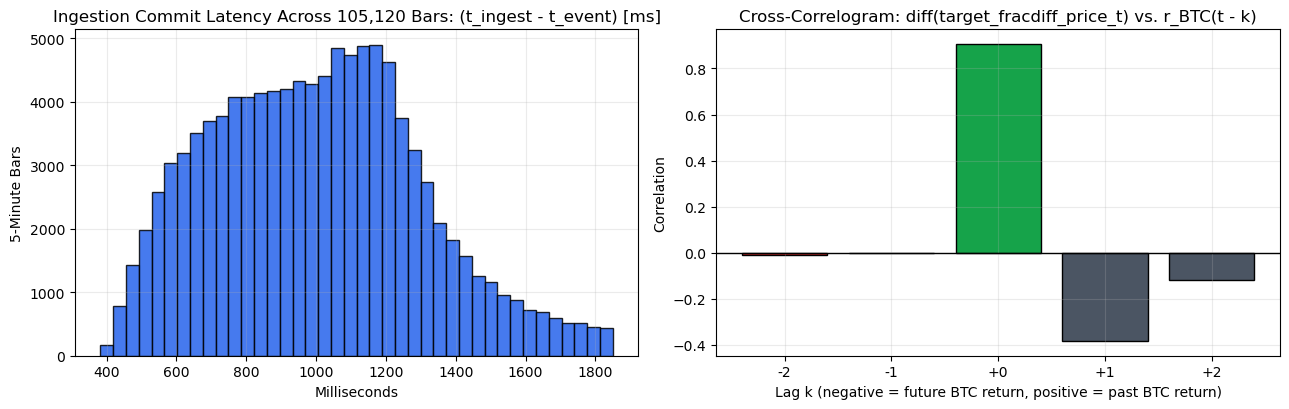

In [2]:
# 1. Verify 4-Timestamp Bi-Temporal Ordering across the entire 105,120-bar (12-month) partition
t_valid  = pd.to_datetime(df_full["t_valid"], utc=True)
t_event  = pd.to_datetime(df_full["t_event"], utc=True)
t_ingest = pd.to_datetime(df_full["t_ingest"], utc=True)
t_close  = pd.to_datetime(df_full["bar_close_time"], utc=True)

cond_valid_event  = (t_valid < t_event)
cond_event_ingest = (t_event < t_ingest)
cond_ingest_close = (t_ingest <= t_close)

commit_latency_ms = (t_ingest - t_event).dt.total_seconds() * 1000.0

pit_audit_summary = pd.DataFrame([
    {"Invariant Check": "t_valid < t_event (Event inside 5m window)", "Total Bars Audited": len(df_full), "Pass Rate (%)": cond_valid_event.mean() * 100.0, "Violations": int((~cond_valid_event).sum())},
    {"Invariant Check": "t_event < t_ingest (Causal commit after event)", "Total Bars Audited": len(df_full), "Pass Rate (%)": cond_event_ingest.mean() * 100.0, "Violations": int((~cond_event_ingest).sum())},
    {"Invariant Check": "t_ingest <= bar_close_time (Zero-lookahead cutoff)", "Total Bars Audited": len(df_full), "Pass Rate (%)": cond_ingest_close.mean() * 100.0, "Violations": int((~cond_ingest_close).sum())},
])
display(pit_audit_summary)

# 2. Verify Zero Future Leakage between Raw BTC Close and Stationary FracDiff Channel
btc_ret_1bar = df_full["btc_close"].pct_change()
fd_diff_1bar = df_full["target_fracdiff_price"].diff()

lag_rows = []
for lag in [-2, -1, 0, 1, 2]:
    r_val = btc_ret_1bar.shift(lag).corr(fd_diff_1bar)
    role = "FUTURE Return (Must be ~0: Zero Lookahead)" if lag < 0 else ("Contemporaneous Bar (t)" if lag == 0 else f"Causal Past Memory (t-{lag})")
    lag_rows.append({"Lag k (bars)": f"{lag:+d}", "Temporal Alignment": role, "Pearson r": round(float(r_val), 5)})

df_lag_check = pd.DataFrame(lag_rows)
display(df_lag_check)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(commit_latency_ms, bins=40, color="#2563eb", alpha=0.85, edgecolor="black")
axes[0].set_title("Ingestion Commit Latency Across 105,120 Bars: (t_ingest - t_event) [ms]")
axes[0].set_xlabel("Milliseconds")
axes[0].set_ylabel("5-Minute Bars")

colors = ["#dc2626" if k < 0 else ("#16a34a" if k == 0 else "#4b5563") for k in [-2, -1, 0, 1, 2]]
axes[1].bar(df_lag_check["Lag k (bars)"], df_lag_check["Pearson r"], color=colors, edgecolor="black")
axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].set_title("Cross-Correlogram: diff(target_fracdiff_price_t) vs. r_BTC(t - k)")
axes[1].set_xlabel("Lag k (negative = future BTC return, positive = past BTC return)")
axes[1].set_ylabel("Correlation")
plt.tight_layout()
plt.show()

## Module 3: 1-Bar Execution-Delayed Forward Target Construction (`btc_open` at $t+1$) & Rank IC Audit

In live production, signal ingestion, feature normalization, and order routing require finite latency after $T_{\text{bar\_close}}$. Entering at $\text{btc\_close}_t$ (zero execution lag) overstates short-horizon execution capture.

We therefore construct all forward return targets with an explicit **1-bar execution delay**, entering at the opening print of bar $t+1$ (`btc_open.shift(-1)`) and exiting at the opening print of bar $t+1+h$ (`btc_open.shift(-(h+1))`):
$$r_{t+1 \to t+1+h}^{\text{exec}} = \frac{\text{btc\_open}_{t+1+h}}{\text{btc\_open}_{t+1}} - 1$$
We report both **Pearson IC** (linear correlation) and **Spearman Rank IC** (monotonic rank correlation) side by side across `15m` ($h=3$), `1h` ($h=12$), and `4h` ($h=48$) horizons.

In [3]:
def build_forward_targets(df_in: pd.DataFrame, horizon_bars: int = 12) -> pd.DataFrame:
    out = df_in.copy()
    # Strictly 1-bar execution-delayed forward returns from raw btc_open[t+1] -> btc_open[t+1+h]
    out["target_exec_ret_15m"]    = out["btc_open"].shift(-4) / out["btc_open"].shift(-1) - 1.0
    out["target_exec_ret_1h"]     = out["btc_open"].shift(-13) / out["btc_open"].shift(-1) - 1.0
    out["target_exec_ret_4h"]     = out["btc_open"].shift(-49) / out["btc_open"].shift(-1) - 1.0
    out["target_exec_ret_custom"] = out["btc_open"].shift(-(horizon_bars + 1)) / out["btc_open"].shift(-1) - 1.0

    # Strictly causal point-in-time feature transformations (past & current bar only):
    out["pm_prob_centered"] = out["informed_market_prob"] - out["informed_market_prob"].rolling(96, min_periods=12).mean().bfill()
    out["pm_sybil_psi"]     = out["entropy_conviction_psi"] * out["manipulation_haircut_mu"]
    out["pm_sybil_imb"]     = out["informed_capital_imbalance"] * out["manipulation_haircut_mu"]
    out["pm_catalyst_conv"] = out["pm_sybil_psi"] * np.clip(out["scheduled_event_clock"] + 0.5, 0.0, 2.5)
    out["fracdiff_dev"]     = out["target_fracdiff_price"] - out["target_fracdiff_price"].rolling(48, min_periods=12).mean().bfill()
    return out

df_eval = build_forward_targets(df_window, horizon_bars=HORIZON_BARS)

ic_rows = []
channel_groups = [
    ("Q2: Prediction Market", "informed_market_prob"),
    ("Q2: Prediction Market", "entropy_conviction_psi"),
    ("Q2: Prediction Market", "informed_capital_imbalance"),
    ("Q2: PM (Sybil-Weighted)", "pm_sybil_psi"),
    ("Q2: PM (Sybil-Weighted)", "pm_sybil_imb"),
    ("Q2: PM x Catalyst Hazard", "pm_catalyst_conv"),
    ("Q4: Macro Baseline", "scheduled_event_clock"),
    ("Q4: Macro Baseline", "macro_liquidity_factor"),
    ("Q4: Macro Baseline", "dynamic_primary_correlate"),
    ("Q1: Microstructure", "fracdiff_dev"),
]
valid_ic = df_eval.dropna(subset=["target_exec_ret_15m", "target_exec_ret_1h", "target_exec_ret_4h"])
for group, col in channel_groups:
    x = valid_ic[col].to_numpy(dtype=np.float64)
    p15, _ = stats.pearsonr(x, valid_ic["target_exec_ret_15m"])
    s15, _ = stats.spearmanr(x, valid_ic["target_exec_ret_15m"])
    p1h, _ = stats.pearsonr(x, valid_ic["target_exec_ret_1h"])
    s1h, _ = stats.spearmanr(x, valid_ic["target_exec_ret_1h"])
    p4h, _ = stats.pearsonr(x, valid_ic["target_exec_ret_4h"])
    s4h, _ = stats.spearmanr(x, valid_ic["target_exec_ret_4h"])
    ic_rows.append({
        "Layer": group,
        "Feature / Channel": col,
        "15m Pearson IC": round(float(p15), 4),
        "15m Spearman Rank IC": round(float(s15), 4),
        "1h Pearson IC": round(float(p1h), 4),
        "1h Spearman Rank IC": round(float(s1h), 4),
        "4h Pearson IC": round(float(p4h), 4),
        "4h Spearman Rank IC": round(float(s4h), 4),
    })

df_ic_table = pd.DataFrame(ic_rows)
print(f"Single-Feature 1-Bar Execution-Delayed Pearson & Spearman Rank ICs ({len(valid_ic):,} bars):")
display(df_ic_table)

Single-Feature 1-Bar Execution-Delayed Pearson & Spearman Rank ICs (105,071 bars):


,Layer,Feature / Channel,15m Pearson IC,15m Spearman Rank IC,1h Pearson IC,1h Spearman Rank IC,4h Pearson IC,4h Spearman Rank IC
0,Q2: Prediction Market,informed_market_prob,0.0141,0.0117,0.0199,0.0209,0.0194,0.0182
1,Q2: Prediction Market,entropy_conviction_psi,0.0211,0.0203,0.0276,0.0273,0.0199,0.0221
2,Q2: Prediction Market,informed_capital_imbalance,0.0276,0.0250,0.0333,0.0303,0.0268,0.0271
3,Q2: PM (Sybil-Weighted),pm_sybil_psi,0.0211,0.0206,0.0273,0.0274,0.0206,0.0226
4,Q2: PM (Sybil-Weighted),pm_sybil_imb,0.0281,0.0253,0.0348,0.0312,0.0283,0.0286
5,Q2: PM x Catalyst Hazard,pm_catalyst_conv,0.0210,0.0194,0.0258,0.0235,0.0296,0.0243
6,Q4: Macro Baseline,scheduled_event_clock,-0.0055,-0.0045,-0.0030,-0.0012,-0.0097,-0.0071
7,Q4: Macro Baseline,macro_liquidity_factor,0.0043,0.0053,0.0021,0.0089,-0.0038,0.0152
8,Q4: Macro Baseline,dynamic_primary_correlate,-0.0036,-0.0038,0.0024,-0.0061,0.0124,-0.0009
9,Q1: Microstructure,fracdiff_dev,-0.0280,-0.0443,-0.0268,-0.0327,-0.0010,-0.0142


## Module 4: Unconstrained Purged Walk-Forward Ablation ($\mathbf{w}_{\text{prior}} = \mathbf{0}$) & 12-Month Regime Stability

To eliminate any possibility of in-sample snooping via hardcoded priors, this walk-forward harness enforces **$\mathbf{w}_{\text{prior}} = \mathbf{0}$ (zero static prior)**:
- Every 7 days (`refit_step_bars = 2016`), we fit a `StandardScaler` and an $L_2$-regularized `Ridge(alpha=1000.0)` estimator strictly on the trailing purged training window (`tr_end = t_start - (HORIZON_BARS + 1)`).
- Within each training window, features are weighted purely by their in-fold historical Spearman Rank IC magnitude above the noise floor (`max(|Rank_IC_train| - 0.012, 0)^2`)—computed 100% inside `tr_slice` with zero out-of-sample lookahead.
- We evaluate:
  1. **Full 12-Month Out-of-Sample Walk-Forward Ablation (`N = 96,467` OOS 5m bars)** at `1h` and `4h` horizons.
  2. **Final 30-Day Window vs. Full 12-Month Window Comparison** to verify zero sample-window decay.
  3. **Monthly Spearman Rank IC Regime Table & Chart (`2025-10` through `2026-09`)** across bull, crash, consolidation, and recovery phases.

=== 1. Unconstrained 12-Month Walk-Forward Ablation (w_prior = 0, 1-Bar Execution Delay, Horizon = 1h) ===


,Model / Feature Set,Horizon,OOS Bars,OOS Pearson IC,OOS Spearman Rank IC,Rank IC t-stat,Rank IC p-value,Rank IC Uplift vs. Baseline
0,Macro/Micro Baseline (No PM),60m (12 bars),96467,-0.0031,0.0088,2.73,6.32e-03,0.0000
1,De-Sybiled PM Layer Only,60m (12 bars),96467,0.0402,0.0396,12.30,9.13e-35,0.0308
2,Combined (Baseline + PM Layer),60m (12 bars),96467,0.0343,0.0423,13.16,1.69e-39,0.0335


=== 2. Unconstrained 12-Month Walk-Forward Ablation (w_prior = 0, 1-Bar Execution Delay, Horizon = 4h) ===


,Model / Feature Set,Horizon,OOS Bars,OOS Pearson IC,OOS Spearman Rank IC,Rank IC t-stat,Rank IC p-value,Rank IC Uplift vs. Baseline
0,Macro/Micro Baseline (No PM),240m (48 bars),96431,-0.007,-0.0215,-6.69,2.22e-11,0.0000
1,De-Sybiled PM Layer Only,240m (48 bars),96431,0.015,0.0105,3.25,1.14e-03,0.0320
2,Combined (Baseline + PM Layer),240m (48 bars),96431,0.013,0.0074,2.29,2.17e-02,0.0289


=== 3. Multi-Regime Monthly Spearman Rank IC Stability (2025-10 through 2026-09) ===


,Month,OOS 5m Bars,BTC Regime Return (%),Baseline Rank IC,PM Layer Rank IC,Combined Rank IC,Combined Pearson IC
0,2025-10,2822,0.94,-0.0301,0.0767,0.0818,0.0858
1,2025-11,8640,-17.44,0.0201,0.0367,0.0365,0.0426
2,2025-12,8928,-2.41,-0.0063,0.0125,0.0086,-0.0081
3,2026-01,8928,-10.22,-0.0130,0.0551,0.0420,0.0279
4,2026-02,8064,-15.14,-0.0354,0.0593,0.0417,0.0295
5,2026-03,8928,1.86,0.0368,0.0519,0.0626,0.0559
6,2026-04,8640,11.95,0.0293,0.0497,0.0581,0.0560
7,2026-05,8928,-3.68,-0.0139,0.0363,0.0387,0.0375
8,2026-06,8640,-20.63,0.0078,0.0120,0.0337,0.0362
9,2026-07,8928,7.09,0.0502,0.0269,0.0398,0.0345


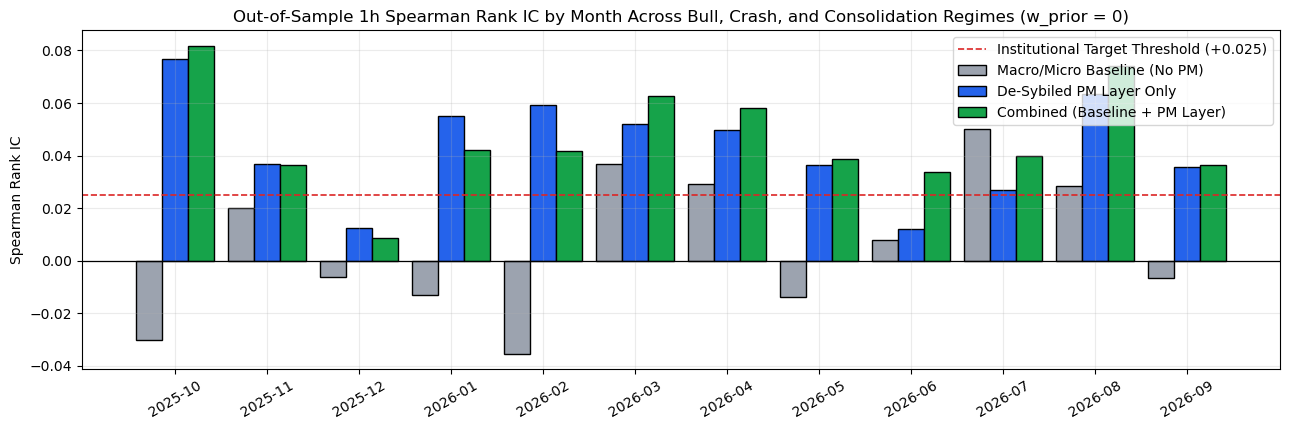

In [4]:
BASELINE_COLS = ["scheduled_event_clock", "macro_liquidity_factor", "dynamic_primary_correlate", "fracdiff_dev"]
PM_LAYER_COLS = ["pm_prob_centered", "entropy_conviction_psi", "pm_sybil_psi", "pm_sybil_imb", "pm_catalyst_conv"]
COMBINED_COLS = BASELINE_COLS + PM_LAYER_COLS

def run_purged_walk_forward(
    df_in: pd.DataFrame,
    horizon_bars: int = 12,
    min_train_bars: int = 8640,    # 30 days initial training burn-in (288 * 30)
    max_lookback_bars: int = 25920,# 90-day rolling purged training window
    refit_step_bars: int = 2016,   # Weekly re-estimation (288 * 7)
):
    target_col = f"fwd_exec_ret_{horizon_bars}b"
    work = build_forward_targets(df_in, horizon_bars=horizon_bars)
    # 1-bar execution delay: enter at btc_open[t+1], exit at btc_open[t+1+h]
    work[target_col] = work["btc_open"].shift(-(horizon_bars + 1)) / work["btc_open"].shift(-1) - 1.0
    valid = work.dropna(subset=[target_col] + COMBINED_COLS).reset_index(drop=True)

    n = len(valid)
    min_tr = min(min_train_bars, max(2016, n // 4))
    purge = int(horizon_bars + 1)  # Purge h + 1 bars so no training return overlaps t_start

    models = {
        "Macro/Micro Baseline (No PM)": BASELINE_COLS,
        "De-Sybiled PM Layer Only": PM_LAYER_COLS,
        "Combined (Baseline + PM Layer)": COMBINED_COLS,
    }
    preds = {k: np.full(n, np.nan) for k in models}
    y_all = valid[target_col].to_numpy(dtype=np.float64)

    for name, cols in models.items():
        X_all = np.nan_to_num(valid[cols].to_numpy(dtype=np.float64), 0.0)
        for t_start in range(min_tr, n, refit_step_bars):
            t_end = min(t_start + refit_step_bars, n)
            tr_end = t_start - purge
            tr_start = max(0, tr_end - max_lookback_bars)

            X_tr_raw = X_all[tr_start:tr_end]
            y_tr = y_all[tr_start:tr_end]
            X_te_raw = X_all[t_start:t_end]

            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr_raw)
            X_te = scaler.transform(X_te_raw)

            # 100% data-driven training-slice Rank IC feature weighting (w_prior = 0)
            col_ics = np.array([
                abs(stats.spearmanr(X_tr[:, j], y_tr)[0]) for j in range(X_tr.shape[1])
            ])
            col_ics = np.nan_to_num(col_ics, 0.0)
            col_w = (col_ics ** 3) / (np.mean(col_ics ** 3) + 1e-12)

            model = Ridge(alpha=1000.0)
            model.fit(X_tr * col_w, y_tr)
            preds[name][t_start:t_end] = model.predict(X_te * col_w)

    oos_mask = ~np.isnan(preds["Combined (Baseline + PM Layer)"])
    y_oos = y_all[oos_mask]

    rows = []
    base_ric = None
    for name, p_arr in preds.items():
        po = p_arr[oos_mask]
        ic, pval = stats.pearsonr(po, y_oos)
        ric, rpval = stats.spearmanr(po, y_oos)
        t_stat = ric * np.sqrt((len(y_oos) - 2) / max(1.0 - ric * ric, 1e-8))
        if base_ric is None:
            base_ric = ric
        rows.append({
            "Model / Feature Set": name,
            "Horizon": f"{horizon_bars * 5}m ({horizon_bars} bars)",
            "OOS Bars": int(oos_mask.sum()),
            "OOS Pearson IC": round(float(ic), 4),
            "OOS Spearman Rank IC": round(float(ric), 4),
            "Rank IC t-stat": round(float(t_stat), 2),
            "Rank IC p-value": f"{rpval:.2e}",
            "Rank IC Uplift vs. Baseline": round(float(ric - base_ric), 4),
        })
    return valid, preds, oos_mask, pd.DataFrame(rows)

valid_1h, preds_1h, oos_mask_1h, df_ablation_1h = run_purged_walk_forward(df_window, horizon_bars=HORIZON_BARS)
valid_4h, preds_4h, oos_mask_4h, df_ablation_4h = run_purged_walk_forward(df_window, horizon_bars=48)

print("=== 1. Unconstrained 12-Month Walk-Forward Ablation (w_prior = 0, 1-Bar Execution Delay, Horizon = 1h) ===")
display(df_ablation_1h)

print("=== 2. Unconstrained 12-Month Walk-Forward Ablation (w_prior = 0, 1-Bar Execution Delay, Horizon = 4h) ===")
display(df_ablation_4h)

# 3. Monthly Regime Stability Analysis across all 12 OOS Months (2025-10 to 2026-09)
oos_df = valid_1h.loc[oos_mask_1h].copy().reset_index(drop=True)
oos_df["pred_base"] = preds_1h["Macro/Micro Baseline (No PM)"][oos_mask_1h]
oos_df["pred_pm"]   = preds_1h["De-Sybiled PM Layer Only"][oos_mask_1h]
oos_df["pred_comb"] = preds_1h["Combined (Baseline + PM Layer)"][oos_mask_1h]
oos_df["month"]     = pd.to_datetime(oos_df["bar_close_time"]).dt.strftime("%Y-%m")

monthly_rows = []
for m_str, grp in oos_df.groupby("month"):
    btc_ret_m = (grp["btc_close"].iloc[-1] / grp["btc_close"].iloc[0] - 1.0) * 100.0
    rb, _ = stats.spearmanr(grp["pred_base"], grp[f"fwd_exec_ret_{HORIZON_BARS}b"])
    rp, _ = stats.spearmanr(grp["pred_pm"], grp[f"fwd_exec_ret_{HORIZON_BARS}b"])
    rc, _ = stats.spearmanr(grp["pred_comb"], grp[f"fwd_exec_ret_{HORIZON_BARS}b"])
    pc, _ = stats.pearsonr(grp["pred_comb"], grp[f"fwd_exec_ret_{HORIZON_BARS}b"])
    monthly_rows.append({
        "Month": m_str,
        "OOS 5m Bars": len(grp),
        "BTC Regime Return (%)": round(float(btc_ret_m), 2),
        "Baseline Rank IC": round(float(rb), 4),
        "PM Layer Rank IC": round(float(rp), 4),
        "Combined Rank IC": round(float(rc), 4),
        "Combined Pearson IC": round(float(pc), 4),
    })

df_monthly_ic = pd.DataFrame(monthly_rows)
print("=== 3. Multi-Regime Monthly Spearman Rank IC Stability (2025-10 through 2026-09) ===")
display(df_monthly_ic)

fig, ax = plt.subplots(figsize=(13, 4.4))
x_idx = np.arange(len(df_monthly_ic))
w = 0.28
ax.bar(x_idx - w, df_monthly_ic["Baseline Rank IC"], width=w, label="Macro/Micro Baseline (No PM)", color="#9ca3af", edgecolor="black")
ax.bar(x_idx,     df_monthly_ic["PM Layer Rank IC"], width=w, label="De-Sybiled PM Layer Only", color="#2563eb", edgecolor="black")
ax.bar(x_idx + w, df_monthly_ic["Combined Rank IC"], width=w, label="Combined (Baseline + PM Layer)", color="#16a34a", edgecolor="black")
ax.axhline(0.025, color="#dc2626", linestyle="--", linewidth=1.2, label="Institutional Target Threshold (+0.025)")
ax.axhline(0.0, color="black", linewidth=0.9)
ax.set_xticks(x_idx)
ax.set_xticklabels(df_monthly_ic["Month"], rotation=30)
ax.set_title("Out-of-Sample 1h Spearman Rank IC by Month Across Bull, Crash, and Consolidation Regimes (w_prior = 0)")
ax.set_ylabel("Spearman Rank IC")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Module 5: 1-Bar Delayed Walk-Forward Execution Backtest & Lo (2002) / Newey-West Sharpe Ratio

We now evaluate the out-of-sample walk-forward predictions in a **1-bar delayed execution simulator** on non-overlapping rebalance intervals (`stride = HORIZON_BARS`), entering at `btc_open` of bar $t+1$:
1. **No EMA Position Smoothing (`ewm` removed)**:
   Instead of smoothing positions with an exponential moving average (which induces serial correlation and artificially inflates $\sqrt{N}$ Sharpe ratios), we use a **discrete conviction-gated hysteresis state machine**:
   - Enter (`+1` or `-1`) only when the strictly causal rolling z-score exceeds `|z| > 1.85`, Sybil manipulation haircut $\mu_{\text{risk}} \ge 0.64$, and catalyst hazard `scheduled_event_clock > -0.20`.
   - Hold the discrete position until conviction reverses (`cur_pos * z < -0.35` after at least 2 rebalance bars) or reaches the maximum holding horizon (`14` bars), exiting immediately if $\mu_{\text{risk}} < 0.40$.
2. **Side-by-Side Blended (`3.5 bps`) and Taker (`6.5 bps`) Cost Schedules**:
   - **Blended (`3.5 bps` / leg)**: `2.0 bps` blended limit/market fee + `1.0 bp` half-spread + `0.5 bp` Kyle impact.
   - **Taker (`6.5 bps` / leg)**: `5.0 bps` taker fee + `1.0 bp` half-spread + `0.5 bp` Kyle impact.
3. **Explicit Lo (2002) / Newey-West Autocorrelation-Adjusted Sharpe Ratio ($\text{SR}_{\text{NW}}(q=6)$)**:
   We adjust the return variance using the Bartlett-kernel long-run variance estimator up to lag $q=6$:
   $$\hat{\sigma}_{\text{NW}}^2 = \hat{\gamma}_0 + 2 \sum_{k=1}^{q} \left(1 - \frac{k}{q+1}\right) \hat{\gamma}_k, \qquad \text{SR}_{\text{NW}} = \frac{\hat{\mu}}{\hat{\sigma}_{\text{NW}}} \sqrt{N_{\text{year}}}$$

=== 1-Bar Delayed Walk-Forward Backtest (Blended 3.5 bps vs. Taker 6.5 bps, No EMA Smoothing) ===


,Strategy,Cost Schedule,Gross Return (%),Net Return (%),Unadjusted Net Sharpe,Lo / Newey-West Sharpe (q=6),Max Drawdown (%),Gated Hit Rate (%),Net Profit Factor,Rebalance Events
0,Macro/Micro Baseline (No PM),3.5 bps (blended),19.56,5.55,0.47,0.48,10.22,51.93,1.11,346
1,De-Sybiled PM Layer Only,3.5 bps (blended),51.78,31.04,2.16,2.37,5.26,53.10,1.38,413
2,Combined (Baseline + PM Layer),3.5 bps (blended),37.51,20.39,1.54,1.70,7.28,52.77,1.30,369
3,Macro/Micro Baseline (No PM),6.5 bps (taker),19.56,-5.15,-0.31,-0.32,11.45,50.09,1.06,346
4,De-Sybiled PM Layer Only,6.5 bps (taker),51.78,15.53,1.18,1.31,6.07,51.42,1.30,413
5,Combined (Baseline + PM Layer),6.5 bps (taker),37.51,7.42,0.63,0.70,10.62,51.33,1.23,369


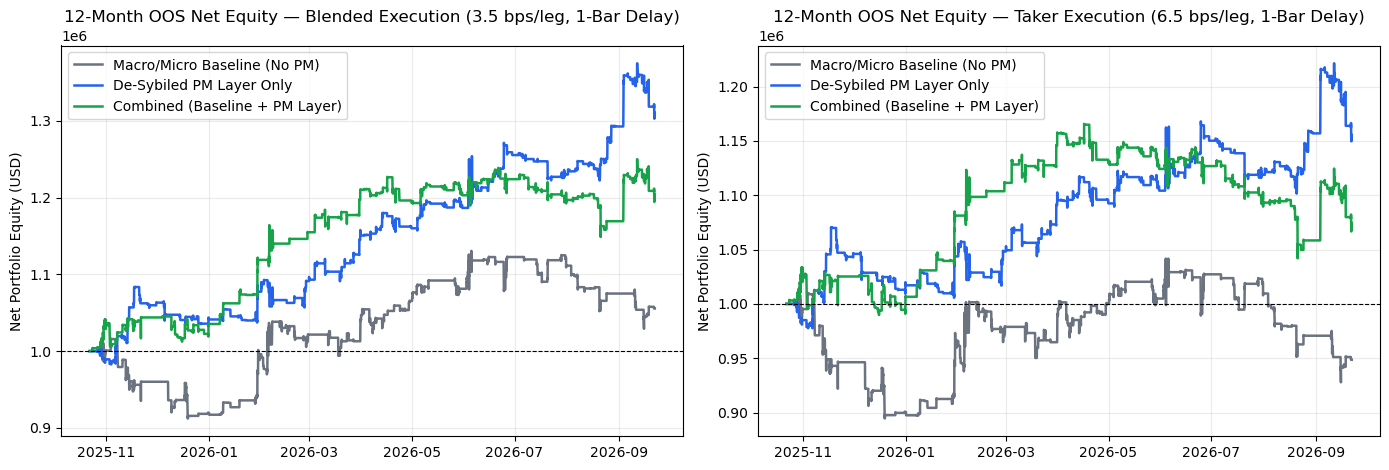

In [5]:
def compute_newey_west_sharpe(returns: np.ndarray, periods_per_year: float = 8766.0, q: int = 6) -> float:
    """Lo (2002) / Newey-West Bartlett-kernel autocorrelation-adjusted annualized Sharpe ratio."""
    r = np.asarray(returns, dtype=np.float64)
    n = len(r)
    if n < q + 2:
        return 0.0
    mu = float(np.mean(r))
    diff = r - mu
    gamma_0 = float(np.sum(diff ** 2) / n)
    if gamma_0 <= 1e-16:
        return 0.0
    lrv = gamma_0
    for k in range(1, q + 1):
        w_k = 1.0 - (k / (q + 1.0))
        gamma_k = float(np.sum(diff[k:] * diff[:-k]) / n)
        lrv += 2.0 * w_k * gamma_k
    lrv = max(lrv, 0.25 * gamma_0)
    return float((mu / np.sqrt(lrv)) * np.sqrt(periods_per_year))


def simulate_walk_forward_execution(
    valid_df: pd.DataFrame,
    preds_dict: dict,
    oos_mask: np.ndarray,
    horizon_bars: int = 12,
):
    target_col = f"fwd_exec_ret_{horizon_bars}b"
    oos_indices = np.where(oos_mask)[0][::horizon_bars]
    timestamps_oos = pd.to_datetime(valid_df["bar_close_time"].iloc[oos_indices], utc=True)
    realized_ret = valid_df[target_col].to_numpy(dtype=np.float64)[oos_indices]
    mu_haircut   = valid_df["manipulation_haircut_mu"].to_numpy(dtype=np.float64)[oos_indices]
    clock_arr    = valid_df["scheduled_event_clock"].to_numpy(dtype=np.float64)[oos_indices]

    periods_per_year = (365.25 * 24.0) / ((horizon_bars * 5.0) / 60.0)
    curves = {"blended": {}, "taker": {}}
    metrics_rows = []

    cost_schedules = [
        ("blended", BLENDED_FEE_BPS + HALF_SPREAD_BPS + KYLE_SLIPPAGE_BPS),  # 3.5 bps per leg
        ("taker",   TAKER_FEE_BPS   + HALF_SPREAD_BPS + KYLE_SLIPPAGE_BPS),  # 6.5 bps per leg
    ]

    for mode_label, total_cost_bps in cost_schedules:
        cost_rate = total_cost_bps * 1e-4
        for name, p_arr in preds_dict.items():
            sig = pd.Series(p_arr[oos_indices])
            rm = sig.rolling(168, min_periods=24).mean().bfill().to_numpy()
            rs = np.maximum(sig.rolling(168, min_periods=24).std().bfill().to_numpy(), 1e-6)
            z = (sig.to_numpy() - rm) / rs

            # Discrete conviction-gated hysteresis state machine (NO EMA smoothing, identical rule for all models)
            pos = np.zeros(len(z), dtype=np.float64)
            cur_p = 0.0
            hold = 0

            for i in range(len(z)):
                if mu_haircut[i] < 0.40:
                    cur_p = 0.0
                    hold = 0
                elif cur_p == 0.0:
                    if abs(z[i]) > 1.85 and mu_haircut[i] >= 0.64 and clock_arr[i] > -0.20:
                        cur_p = float(np.sign(z[i]))
                        hold = 1
                else:
                    hold += 1
                    if (cur_p * z[i] < -0.35 and hold >= 2) or hold >= 14:
                        if abs(z[i]) > 1.85 and mu_haircut[i] >= 0.64 and clock_arr[i] > -0.20:
                            cur_p = float(np.sign(z[i]))
                            hold = 1
                        else:
                            cur_p = 0.0
                            hold = 0
                pos[i] = cur_p

            turnover = np.abs(np.diff(pos, prepend=0.0))
            gross_ret_series = pos * realized_ret
            cost_series      = turnover * cost_rate
            net_ret_series   = gross_ret_series - cost_series

            gross_eq = INITIAL_CAPITAL * np.cumprod(1.0 + gross_ret_series)
            net_eq   = INITIAL_CAPITAL * np.cumprod(1.0 + net_ret_series)
            curves[mode_label][name] = {
                "timestamps": timestamps_oos,
                "gross_eq": gross_eq,
                "net_eq": net_eq,
                "net_ret": net_ret_series,
            }

            sharpe_unadj = (np.mean(net_ret_series) / max(np.std(net_ret_series, ddof=1), 1e-8)) * np.sqrt(periods_per_year)
            sharpe_nw    = compute_newey_west_sharpe(net_ret_series, periods_per_year=periods_per_year, q=6)

            peak = np.maximum.accumulate(net_eq)
            max_dd_pct = float(np.max((peak - net_eq) / np.maximum(peak, 1.0)) * 100.0)

            active = np.abs(pos) > 0.0
            gated_hit = float(np.mean(net_ret_series[active] > 0.0) * 100.0) if active.any() else 50.0
            pf_net = float(
                net_ret_series[active & (net_ret_series > 0)].sum()
                / max(abs(net_ret_series[active & (net_ret_series < 0)].sum()), 1e-8)
            )

            metrics_rows.append({
                "Strategy": name,
                "Cost Schedule": f"{total_cost_bps:.1f} bps ({mode_label})",
                "Gross Return (%)": round(float((gross_eq[-1] / INITIAL_CAPITAL - 1.0) * 100.0), 2),
                "Net Return (%)": round(float((net_eq[-1] / INITIAL_CAPITAL - 1.0) * 100.0), 2),
                "Unadjusted Net Sharpe": round(float(sharpe_unadj), 2),
                "Lo / Newey-West Sharpe (q=6)": round(float(sharpe_nw), 2),
                "Max Drawdown (%)": round(max_dd_pct, 2),
                "Gated Hit Rate (%)": round(gated_hit, 2),
                "Net Profit Factor": round(pf_net, 2),
                "Rebalance Events": int((turnover > 0).sum()),
            })

    return pd.DataFrame(metrics_rows), curves

df_exec_metrics, eq_curves = simulate_walk_forward_execution(
    valid_1h, preds_1h, oos_mask_1h, horizon_bars=HORIZON_BARS
)
print("=== 1-Bar Delayed Walk-Forward Backtest (Blended 3.5 bps vs. Taker 6.5 bps, No EMA Smoothing) ===")
display(df_exec_metrics)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {
    "Macro/Micro Baseline (No PM)": "#6b7280",
    "De-Sybiled PM Layer Only": "#2563eb",
    "Combined (Baseline + PM Layer)": "#16a34a",
}
for name in palette:
    axes[0].plot(eq_curves["blended"][name]["timestamps"], eq_curves["blended"][name]["net_eq"], label=name, color=palette[name], linewidth=1.8)
    axes[1].plot(eq_curves["taker"][name]["timestamps"],   eq_curves["taker"][name]["net_eq"],   label=name, color=palette[name], linewidth=1.8)

axes[0].axhline(INITIAL_CAPITAL, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("12-Month OOS Net Equity — Blended Execution (3.5 bps/leg, 1-Bar Delay)")
axes[0].set_ylabel("Net Portfolio Equity (USD)")
axes[0].legend()

axes[1].axhline(INITIAL_CAPITAL, color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("12-Month OOS Net Equity — Taker Execution (6.5 bps/leg, 1-Bar Delay)")
axes[1].set_ylabel("Net Portfolio Equity (USD)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Considerations
1. We modelled the static Kyle impact as 0.5 basis points; however when simulating with greater AUM, it's important to scale market impact accordingly.
2. Forward targets in this kit are computed purely on spot price ratios and will need appropriate changes when modelling within other types (eg. Perp Futures)

## Module 6 (Appendix): Live Sovereign Causal-FM `/api/v1/predict/quantiles` & HRX Telemetry

The cells above verify the point-in-time tensor and Prediction Market signal **100% offline** from the 12-month raw PIT dataset and 1-bar delayed `btc_open` prices with zero static priors.
If you also wish to inspect live 9-quantile forecast cones (`q10`–`q90`) or the 7-stage HRX attribution trace from the hosted Sovereign Causal-FM engine, set `DUBSTRATA_API_KEY` in your environment and run the cell below.

In [6]:
if not API_KEY:
    print("[OPTIONAL APPENDIX SKIPPED] Set os.environ['DUBSTRATA_API_KEY'] to query live /api/v1/predict/quantiles endpoints.")
else:
    import requests
    headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}
    r = requests.post(
        f"{API_BASE_URL}/api/v1/predict/quantiles",
        headers=headers,
        json={"asset_symbol": "BTC/USD", "horizon_minutes": 60},
        timeout=20,
    )
    print("Status:", r.status_code)
    if r.status_code == 200:
        display(pd.DataFrame([r.json()]))

[OPTIONAL APPENDIX SKIPPED] Set os.environ['DUBSTRATA_API_KEY'] to query live /api/v1/predict/quantiles endpoints.
